<a href="https://colab.research.google.com/github/anupbagale/ssl-brain-parcellation/blob/main/notebooks/02_clinical_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Subject-level analysis

Joins the per-subject test Dice from notebook 01 with OASIS-3 participant data
(age, sex, MMSE, CDR, scanner). CPU runtime is enough.

The metadata CSV is not included in this repository (OASIS data use agreement).
Required columns: `image_name, OASISID, age_at_scan, sex, MMSE, CDR_global, scanner_model`.

Per-subject scores are stored in the same order as `folds.json[k]['test']`
because the test loader in notebook 01 uses `shuffle=False`; this is checked below.

In [ ]:
import os, json, glob
import numpy as np
import pandas as pd
from scipy import stats

from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Paths and metadata

Load the participant table (one row per scan).

In [ ]:
ROOT_DIR = '/content/drive/MyDrive/brain_seg_supervised'
CV_DIR   = os.path.join(ROOT_DIR, 'cv_results')
SSL_DIR  = os.path.join(ROOT_DIR, 'ssl_results')
OUT_DIR  = os.path.join(ROOT_DIR, 'clinical_analysis')
os.makedirs(OUT_DIR, exist_ok=True)

META_CSV = '/content/drive/MyDrive/My_148_images_with_metadata.csv'

meta = pd.read_csv(META_CSV).dropna(subset=['image_name']).reset_index(drop=True)
meta['key'] = meta.image_name.str.replace(r'\.nii(\.gz)?$', '', regex=True)
print(f'metadata rows: {len(meta)}  unique subjects: {meta.OASISID.nunique()}')

metadata rows: 148  unique subjects: 148


## Per-subject Dice

Attach each test subject's Dice from the 5-fold run to its clinical data.

In [ ]:
folds = json.load(open(os.path.join(CV_DIR, 'folds.json')))

def key_of(path):
    return os.path.basename(path).replace('.nii.gz', '').replace('.nii', '')

def collect(result_path_fn, label):
    """Build a per-subject frame from one experimental arm."""
    rows = []
    for f in folds:
        k = f['fold']
        rp = result_path_fn(k)
        if not os.path.exists(rp):
            print(f'  [skip] {label} fold {k}: {os.path.basename(rp)} not found')
            continue
        res  = json.load(open(rp))
        subj = res['per_subject']
        test = f['test']
        assert len(subj) == len(test), (
            f'{label} fold {k}: {len(subj)} scores vs {len(test)} test subjects. '
            'order/length mismatch')
        for path, d in zip(test, subj):
            rows.append({'key': key_of(path), 'fold': k, label: float(d)})
    return pd.DataFrame(rows)

main = collect(lambda k: os.path.join(CV_DIR, f'results_fold{k}.json'), 'dice')
print(f'main CV run: {len(main)} subject scores')
assert len(main) == 148, 'expected 148 subject-level scores'

df = meta.merge(main, on='key', how='inner')
assert len(df) == 148, f'merge lost rows: {len(df)}'

# clinical variables
df['CDR']      = pd.to_numeric(df.CDR_global, errors='coerce')
df['MMSE_n']   = pd.to_numeric(df.MMSE, errors='coerce')
df['age']      = pd.to_numeric(df.age_at_scan, errors='coerce')
df['impaired'] = (df.CDR > 0).astype(int)
df['female']   = (df.sex == 'F').astype(int)
print(df.groupby('CDR').dice.agg(['count', 'mean', 'std']).round(4).to_string())

main CV run: 148 subject scores
     count    mean     std
CDR                       
0.0    112  0.8027  0.0409
0.5     23  0.8000  0.0278
1.0     12  0.7716  0.0758
2.0      1  0.6223     NaN


## Accuracy vs clinical variables

Dice against CDR, MMSE, age, sex and scanner model.

In [ ]:
print('=' * 66)
print('Q1  SUBJECT-LEVEL ASSOCIATIONS WITH SEGMENTATION ACCURACY (n=148)')
print('=' * 66)

def report(x, y, name, kind='spearman'):
    m = x.notna() & y.notna()
    x, y = x[m], y[m]
    if kind == 'spearman':
        r, p = stats.spearmanr(x, y); tag = 'Spearman rho'
    else:
        r, p = stats.pearsonr(x, y);  tag = 'Pearson r   '
    print(f'  {name:<26s} {tag} = {r:+.3f}   p = {p:.4f}   (n={m.sum()})')
    return r, p

report(df.CDR,    df.dice, 'CDR global')
report(df.MMSE_n, df.dice, 'MMSE')
report(df.age,    df.dice, 'age at scan', 'pearson')

print()
a = df.loc[df.impaired == 0, 'dice']; b = df.loc[df.impaired == 1, 'dice']
u, pu = stats.mannwhitneyu(a, b)
t, pt = stats.ttest_ind(a, b, equal_var=False)
print(f'  CDR 0  (n={len(a)}): {a.mean():.4f} +/- {a.std():.4f}')
print(f'  CDR >0 (n={len(b)}): {b.mean():.4f} +/- {b.std():.4f}')
print(f'  difference = {a.mean()-b.mean():+.4f}   Mann-Whitney p={pu:.4f}   Welch t p={pt:.4f}')
pooled = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
print(f"  Cohen's d = {(a.mean()-b.mean())/pooled:.2f}")

print()
f_, pf = stats.f_oneway(*[g.dice.values for _, g in df.groupby('CDR') if len(g) > 1])
h_, ph = stats.kruskal(*[g.dice.values for _, g in df.groupby('CDR') if len(g) > 1])
print(f'  across CDR strata: ANOVA p={pf:.4f}   Kruskal-Wallis p={ph:.4f}')

fem = df.loc[df.female == 1, 'dice']; mal = df.loc[df.female == 0, 'dice']
print(f'\n  female (n={len(fem)}): {fem.mean():.4f}   male (n={len(mal)}): {mal.mean():.4f}   '
      f'Mann-Whitney p={stats.mannwhitneyu(fem, mal)[1]:.4f}')

big = df.groupby('scanner_model').filter(lambda g: len(g) >= 5)
if big.scanner_model.nunique() > 1:
    print('\n  by scanner (models with n>=5):')
    print(big.groupby('scanner_model').dice.agg(['count','mean','std']).round(4).to_string())
    print(f"  Kruskal-Wallis p="
          f"{stats.kruskal(*[g.dice.values for _, g in big.groupby('scanner_model')])[1]:.4f}")

Q1  SUBJECT-LEVEL ASSOCIATIONS WITH SEGMENTATION ACCURACY (n=148)
  CDR global                 Spearman rho = -0.169   p = 0.0403   (n=148)
  MMSE                       Spearman rho = +0.059   p = 0.4786   (n=148)
  age at scan                Pearson r    = -0.003   p = 0.9667   (n=148)

  CDR 0  (n=112): 0.8027 +/- 0.0409
  CDR >0 (n=36): 0.7856 +/- 0.0571
  difference = +0.0171   Mann-Whitney p=0.0590   Welch t p=0.1025
  Cohen's d = 0.38

  across CDR strata: ANOVA p=0.0625   Kruskal-Wallis p=0.1670

  female (n=90): 0.7949   male (n=58): 0.8041   Mann-Whitney p=0.0586

  by scanner (models with n>=5):
               count    mean     std
scanner_model                       
Biograph_mMR      37  0.8261  0.0202
MAGNETOM_Vida      8  0.8214  0.0157
TrioTim          102  0.7868  0.0493
  Kruskal-Wallis p=0.0000


## Multivariable model

Linear model of Dice on age, sex and MMSE. Fold is included as a covariate because each subject was scored by the model of its own fold.

In [ ]:
print('\n' + '=' * 66)
print('Q1b  MULTIVARIABLE MODEL  dice ~ age + sex + MMSE + fold')
print('=' * 66)
try:
    import statsmodels.formula.api as smf
    m = smf.ols('dice ~ age + female + MMSE_n + C(fold)', data=df).fit()
    print(m.summary().tables[1])
    print(f'  R^2 = {m.rsquared:.3f}   n = {int(m.nobs)}')
except Exception as e:
    print('  statsmodels unavailable:', e)


Q1b  MULTIVARIABLE MODEL  dice ~ age + sex + MMSE + fold
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept        0.6855      0.062     11.060      0.000       0.563       0.808
C(fold)[T.1]     0.0026      0.012      0.225      0.822      -0.020       0.025
C(fold)[T.2]     0.0084      0.012      0.715      0.476      -0.015       0.032
C(fold)[T.3]    -0.0256      0.012     -2.180      0.031      -0.049      -0.002
C(fold)[T.4]    -0.0132      0.011     -1.151      0.251      -0.036       0.009
age              0.0004      0.000      0.804      0.423      -0.001       0.001
female          -0.0096      0.008     -1.268      0.207      -0.025       0.005
MMSE_n           0.0034      0.001      2.377      0.019       0.001       0.006
  R^2 = 0.128   n = 148


## Pretraining gain per subject

Difference in Dice between the pretrained and the randomly initialized model for each subject at the full budget (104 labeled scans), and whether it depends on CDR, MMSE or age.

In [ ]:
print('\n' + '=' * 66)
print('Q2  PER-SUBJECT SSL GAIN vs CLINICAL SEVERITY  (full budget)')
print('=' * 66)

ssl_df = collect(lambda k: os.path.join(SSL_DIR, f'results_fold{k}_ssl_n104.json'),     'dice_ssl')
scr_df = collect(lambda k: os.path.join(SSL_DIR, f'results_fold{k}_scratch_n104.json'), 'dice_scr')

if len(ssl_df) and len(scr_df):
    g = (meta[['key','OASISID','sex','age_at_scan','MMSE','CDR_global','scanner_model']]
         .merge(ssl_df, on='key').merge(scr_df.drop(columns=['fold']), on='key'))
    g['gain']   = g.dice_ssl - g.dice_scr
    g['CDR']    = pd.to_numeric(g.CDR_global, errors='coerce')
    g['MMSE_n'] = pd.to_numeric(g.MMSE, errors='coerce')
    g['age']    = pd.to_numeric(g.age_at_scan, errors='coerce')
    g['impaired'] = (g.CDR > 0).astype(int)
    print(f'  paired subjects: {len(g)}')
    print(f'  mean per-subject gain = {g.gain.mean():+.4f} '
          f'(SD {g.gain.std():.4f});  positive in {100*(g.gain>0).mean():.1f}% of subjects')
    t, p = stats.ttest_1samp(g.gain, 0)
    w, pw = stats.wilcoxon(g.gain)
    print(f'  one-sample t p={p:.4g}   Wilcoxon p={pw:.4g}')
    print()
    report(g.CDR, g.gain, 'gain vs CDR')
    report(g.MMSE_n, g.gain, 'gain vs MMSE')
    report(g.age, g.gain, 'gain vs age', 'pearson')
    ga = g.loc[g.impaired == 0, 'gain']; gb = g.loc[g.impaired == 1, 'gain']
    print(f'\n  gain, CDR 0  (n={len(ga)}): {ga.mean():+.4f}')
    print(f'  gain, CDR >0 (n={len(gb)}): {gb.mean():+.4f}')
    print(f'  difference = {gb.mean()-ga.mean():+.4f}   '
          f'Mann-Whitney p={stats.mannwhitneyu(ga, gb)[1]:.4f}')
    g.to_csv(os.path.join(OUT_DIR, 'per_subject_ssl_gain.csv'), index=False)
else:
    print('  n=104 arm result files not found - skipping Q2')
    g = None


Q2  PER-SUBJECT SSL GAIN vs CLINICAL SEVERITY  (full budget)
  paired subjects: 148
  mean per-subject gain = +0.0142 (SD 0.0141);  positive in 87.2% of subjects
  one-sample t p=2.999e-24   Wilcoxon p=5.118e-21

  gain vs CDR                Spearman rho = +0.044   p = 0.5949   (n=148)
  gain vs MMSE               Spearman rho = +0.082   p = 0.3246   (n=148)
  gain vs age                Pearson r    = +0.013   p = 0.8756   (n=148)

  gain, CDR 0  (n=112): +0.0139
  gain, CDR >0 (n=36): +0.0151
  difference = +0.0011   Mann-Whitney p=0.6991


## Figure and tables

Save the figure and the per-subject tables to Drive.

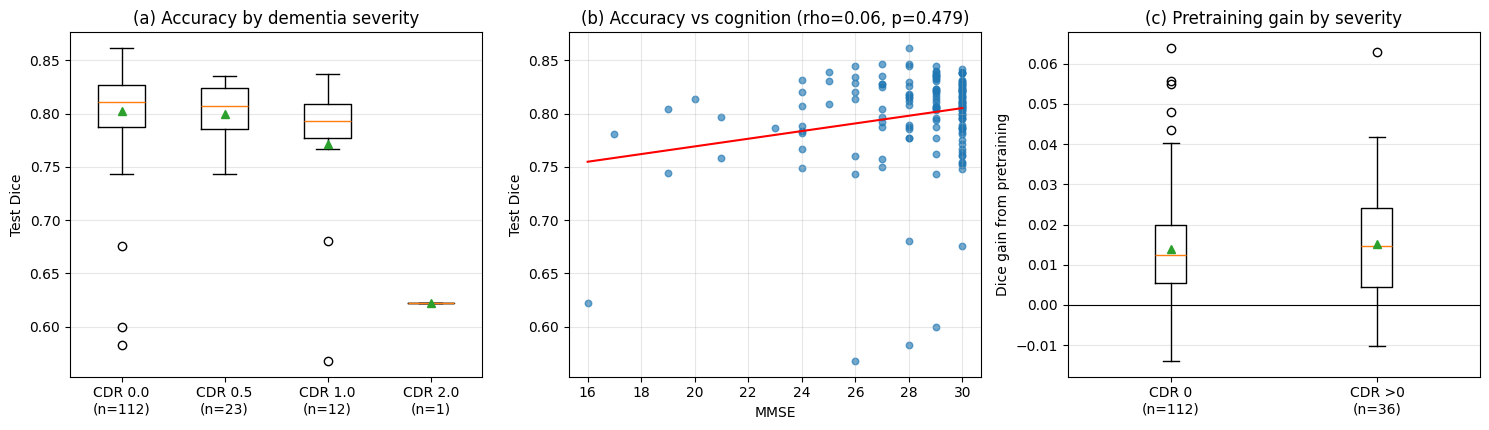


saved to /content/drive/MyDrive/brain_seg_supervised/clinical_analysis
 CDR  count   mean    std
 0.0    112 0.8027 0.0409
 0.5     23 0.8000 0.0278
 1.0     12 0.7716 0.0758
 2.0      1 0.6223    NaN


In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 3, figsize=(15, 4.4))

order = sorted(df.CDR.dropna().unique())
ax[0].boxplot([df.loc[df.CDR == c, 'dice'].values for c in order],
              tick_labels=[f'CDR {c}\n(n={int((df.CDR==c).sum())})' for c in order],
              showmeans=True)
ax[0].set_ylabel('Test Dice'); ax[0].set_title('(a) Accuracy by dementia severity')
ax[0].grid(alpha=.3, axis='y')

ax[1].scatter(df.MMSE_n, df.dice, alpha=.65, s=22)
mm = df.MMSE_n.notna() & df.dice.notna()
b = np.polyfit(df.MMSE_n[mm], df.dice[mm], 1)
xs = np.linspace(df.MMSE_n.min(), df.MMSE_n.max(), 50)
ax[1].plot(xs, np.polyval(b, xs), 'r-', lw=1.5)
r, p = stats.spearmanr(df.MMSE_n[mm], df.dice[mm])
ax[1].set_xlabel('MMSE'); ax[1].set_ylabel('Test Dice')
ax[1].set_title(f'(b) Accuracy vs cognition (rho={r:.2f}, p={p:.3f})')
ax[1].grid(alpha=.3)

if g is not None:
    ax[2].boxplot([g.loc[g.impaired == 0, 'gain'].values,
                   g.loc[g.impaired == 1, 'gain'].values],
                  tick_labels=[f'CDR 0\n(n={int((g.impaired==0).sum())})',
                          f'CDR >0\n(n={int((g.impaired==1).sum())})'], showmeans=True)
    ax[2].axhline(0, c='k', lw=.8)
    ax[2].set_ylabel('Dice gain from pretraining')
    ax[2].set_title('(c) Pretraining gain by severity')
    ax[2].grid(alpha=.3, axis='y')
else:
    ax[2].axis('off')

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'clinical_analysis.png'), dpi=200)
plt.show()

df.to_csv(os.path.join(OUT_DIR, 'per_subject_dice_with_metadata.csv'), index=False)
summary = df.groupby('CDR').dice.agg(['count','mean','std']).round(4).reset_index()
summary.to_csv(os.path.join(OUT_DIR, 'dice_by_cdr.csv'), index=False)
print('\nsaved to', OUT_DIR)
print(summary.to_string(index=False))


## Scanner vs disease

Scanner model and clinical status are confounded in this cohort (more impaired subjects were scanned on TrioTim), so they are tested separately:
A) adjusted model, B) scanners compared within CDR 0 only, C) CDR effect within TrioTim only.

In [ ]:
import statsmodels.formula.api as smf

print('='*70)
print('A.  SCANNER EFFECT, ADJUSTED FOR DISEASE / AGE / SEX / FOLD')
print('='*70)
sub = df[df.scanner_model.isin(['TrioTim','Biograph_mMR','MAGNETOM_Vida'])].copy()
sub['scanner'] = pd.Categorical(sub.scanner_model,
                                categories=['TrioTim','Biograph_mMR','MAGNETOM_Vida'])
m = smf.ols('dice ~ C(scanner) + MMSE_n + CDR + age + female + C(fold)', data=sub).fit()
print(m.summary().tables[1])
print(f'  R^2 = {m.rsquared:.3f}   n = {int(m.nobs)}')

print('\n' + '='*70)
print('B.  SCANNER EFFECT, CDR 0 ONLY')
print('='*70)
cn = df[(df.CDR == 0) & df.scanner_model.isin(['TrioTim','Biograph_mMR'])]
tt = cn[cn.scanner_model == 'TrioTim'].dice
bg = cn[cn.scanner_model == 'Biograph_mMR'].dice
print(f'  TrioTim,  CDR 0 (n={len(tt)}): {tt.mean():.4f} +/- {tt.std():.4f}')
print(f'  Biograph, CDR 0 (n={len(bg)}): {bg.mean():.4f} +/- {bg.std():.4f}')
print(f'  difference = {bg.mean()-tt.mean():+.4f}')
print(f'  Mann-Whitney p = {stats.mannwhitneyu(tt, bg)[1]:.6f}   '
      f'Welch t p = {stats.ttest_ind(tt, bg, equal_var=False)[1]:.6f}')
pool = np.sqrt(((len(tt)-1)*tt.var(ddof=1)+(len(bg)-1)*bg.var(ddof=1))/(len(tt)+len(bg)-2))
print(f"  Cohen's d = {(bg.mean()-tt.mean())/pool:.2f}")
print(f"  Levene (equal variance) p = {stats.levene(tt, bg)[1]:.6f}")

print('\n' + '='*70)
print('C.  DISEASE EFFECT, TrioTim ONLY')
print('='*70)
t_ = df[df.scanner_model == 'TrioTim']
r, p = stats.spearmanr(t_.CDR, t_.dice)
print(f'  TrioTim only (n={len(t_)}): Dice vs CDR  Spearman rho = {r:+.3f}  p = {p:.4f}')
a = t_[t_.CDR == 0].dice; b = t_[t_.CDR > 0].dice
print(f'  CDR 0 (n={len(a)}): {a.mean():.4f}    CDR>0 (n={len(b)}): {b.mean():.4f}   '
      f'diff {a.mean()-b.mean():+.4f}  MW p={stats.mannwhitneyu(a,b)[1]:.4f}')

print('\n' + '='*70)
print('D.  EFFECT SIZES')
print('='*70)
print(f'  scanner (Biograph - TrioTim, CDR 0 only) : {bg.mean()-tt.mean():+.4f} Dice')
print(f'  disease (CDR 0 - CDR>0, TrioTim only)    : {a.mean()-b.mean():+.4f} Dice')
print(f'  SSL pretraining (full budget, per subj)  : {g.gain.mean():+.4f} Dice'
      if g is not None else '  SSL gain: n/a')

print('\n' + '='*70)
print('E.  SSL GAIN BY SCANNER')
print('='*70)
if g is not None:
    for s_, gg in g.groupby('scanner_model'):
        if len(gg) >= 5:
            print(f'  {s_:<15s} n={len(gg):3d}  mean gain = {gg.gain.mean():+.4f} '
                  f'(SD {gg.gain.std():.4f})')
    big = g.groupby('scanner_model').filter(lambda x: len(x) >= 5)
    print(f'  Kruskal-Wallis across scanners: p = '
          f'{stats.kruskal(*[x.gain.values for _, x in big.groupby("scanner_model")])[1]:.4f}')

A.  SCANNER EFFECT, ADJUSTED FOR DISEASE / AGE / SEX / FOLD
                                  coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                       0.7799      0.072     10.837      0.000       0.638       0.922
C(scanner)[T.Biograph_mMR]      0.0313      0.008      3.830      0.000       0.015       0.048
C(scanner)[T.MAGNETOM_Vida]     0.0314      0.016      2.005      0.047       0.000       0.062
C(fold)[T.1]                   -0.0014      0.011     -0.130      0.897      -0.023       0.020
C(fold)[T.2]                    0.0052      0.011      0.465      0.643      -0.017       0.027
C(fold)[T.3]                   -0.0205      0.011     -1.822      0.071      -0.043       0.002
C(fold)[T.4]                   -0.0198      0.011     -1.763      0.080      -0.042       0.002
MMSE_n                          0.0005      0.002      0.280      0.780     